# Reproducing Figure 2: land needed for adequate nutrition, 18 countries

This notebook reproduces this paper's Figure 2 from raw source data: a
country's minimum land requirement (per adult) to reach a given level of
mean nutrient adequacy (MAR), and how that compares to land currently
cultivated by real surveyed households.

It is fully self-contained - only this folder's `data/` and the two `.py`
files alongside this notebook are needed, no other setup. Runtime is a few
minutes (an LP solve per land-grid point per country, ~200 points x 18
countries).

For interactive exploration of the same model (adjustable constraints,
country selection, household composition) see the companion dashboard:
**[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**


## 1. Setup

In [1]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import functions as F
import global_var as GVARS

EXCLUDED_COUNTRIES = {"South Africa"}  # sole country in its macro-area; excluded throughout

## 2. Reference tables

Crop composition is reported per 100g in the source table; the model needs
per-kg values, so every nutrient column is scaled x10 (`edible.prop`, a
fraction rather than a nutrient quantity, is corrected back /=10).

In [2]:
df_composition = pd.read_csv("data/crop_composition_table.csv")
df_composition = df_composition.dropna(subset=["crop"]).set_index("crop")
df_composition = df_composition.fillna(0).replace(" ", 0).astype(float)
df_composition *= 10
df_composition["edible.prop"] /= 10

df_animal = pd.read_excel("data/animal_composition_table_with_carrying_capacity.xlsx", sheet_name="production ha-1")
df_animal = df_animal.set_index("animal").drop(columns=["fat"])

# Dietary reference intake for the paper's reference adult (25-50, male)
df_dri = pd.read_excel("data/food_comp_DRI.xlsx", sheet_name="dietary reference intake")
dri = (df_dri.drop(columns=["fat", "age group", "gender"]).iloc[0] * 365).values  # daily -> annual

## 3. Crop yields, rebuilt from raw FAOSTAT

Maps FAO item names to the model's crop names, fans a few crops out to
sibling crops assumed to share a yield within the same FAO group (e.g.
cabbage's yield also used for kales), then averages by (country, crop).

In [3]:
df_yield = pd.read_csv("data/original/FAOSTAT_data_en_3-25-2026.csv")
df_yield = df_yield[["Item", "Year", "Area", "Value"]]
df_yield = df_yield.rename(columns={"Item": "crop", "Year": "year", "Area": "country", "Value": "yield_per_ha"})
df_yield["crop"] = df_yield["crop"].apply(lambda x: GVARS.mapping_FAO_to_RHOMIS.get(x, None))

duplicates_mapping = {
    "soya_bean": ["soya_bean", "broad_beans"], "peas": ["peas", "field_pea"],
    "millet": ["millet", "fingermillet", "pearl_millet"], "mango": ["mango", "guava"],
    "cabbage": ["cabbage", "kales"], "squash": ["squash", "pumpkin", "zucchini"],
    "sesame": ["sesame", "simsim"], "jackfruit": ["jackfruit", "passion_fruit"],
    "beans": ["beans", "haricot_bean", "green_gram"], "amaranth": ["amaranth", "teff"],
    "watermelon": ["watermelon", "melon"],
}
df_yield["crop"] = df_yield["crop"].apply(lambda x: duplicates_mapping.get(x, [x]))
df_yield = df_yield.explode("crop").reset_index(drop=True).dropna(subset=["crop"])
df_yield = df_yield.groupby(["country", "crop"]).agg({"yield_per_ha": "mean"}).reset_index()
df_yield = df_yield.rename(columns={"yield_per_ha": "mean"})

known_countries = pd.read_csv("data/processed/crop_yield_country.csv")["country"].unique()
df_yield = df_yield[df_yield["country"].isin(known_countries)]
print(f"{len(df_yield)} (country, crop) yield rows across {df_yield['country'].nunique()} countries")

853 (country, crop) yield rows across 19 countries


## 4. Per-country animal-product land caps

Caps land assignable to each animal product, derived from the 95th-
percentile heads-per-person observed for that species in each country x
the animal's livestock-unit factor / the region's carrying capacity.
Countries/species with no observed heads are backfilled with the smallest
positive value seen anywhere (matching the paper's stated rule); eggs
inherit chicken's cap.

In [4]:
heads = pd.read_csv("data/processed/all_heads_per_person_95percentiles.csv")
heads_long = heads.melt(id_vars="id_country", var_name="column", value_name="heads_per_person")
heads_long["animal"] = heads_long["column"].str.split("_").str[3]
heads_long = heads_long.drop(columns=["column"]).dropna(subset=["heads_per_person"])
heads_lookup = {(r.id_country, r.animal): r.heads_per_person for r in heads_long.itertuples()}

ANIMALS = list(GVARS.animal_lsu.keys())
countries_by_id = {k: v for k, v in GVARS.id_country_to_country_name.items() if v not in EXCLUDED_COUNTRIES}

animal_caps = {c: {} for c in countries_by_id.values()}
for id_country, country in countries_by_id.items():
    macro_area = GVARS.country_to_macro_area.get(country)
    lsu_per_ha = GVARS.macro_area_to_lsu_per_ha.get(macro_area)
    if not lsu_per_ha:
        continue
    for animal in ANIMALS:
        hpp = heads_lookup.get((id_country, animal), 0.0)
        animal_caps[country][animal] = hpp * GVARS.animal_lsu[animal] / lsu_per_ha

for animal in ANIMALS:
    positive = [animal_caps[c][animal] for c in animal_caps if animal_caps[c].get(animal, 0) > 0]
    floor = min(positive) if positive else None
    if floor is not None:
        for c in animal_caps:
            if animal_caps[c].get(animal, 0) <= 0:
                animal_caps[c][animal] = floor

for c in animal_caps:
    animal_caps[c]["eggs"] = animal_caps[c].get("chicken", 0.0)

countries = sorted(animal_caps.keys())
print(f"{len(countries)} countries: {countries}")

18 countries: ['Burkina Faso', 'Burundi', 'Comoros', "Côte d'Ivoire", 'Democratic Republic of the Congo', 'Ethiopia', 'Ghana', 'Kenya', 'Malawi', 'Mali', 'Niger', 'Nigeria', 'Rwanda', 'Senegal', 'Sierra Leone', 'Uganda', 'United Republic of Tanzania', 'Zambia']


## 5. Run the LP: MAR vs. land, all countries

For each country, the minimum land needed at ~200 land values
(`np.logspace(-4, 1, 200)`, matching the paper's own grid) is solved for,
maximizing mean adequacy ratio (MAR) subject to caloric, macronutrient, and
per-nutrient upper-limit constraints. This is Figure 2's left panel.

Note: `min_kcal=False` here matches Figure 2's specific generating code -
it drops the minimum-caloric-floor constraint that the model uses by
default elsewhere, deliberately, for this figure.

In [5]:
land_values = np.logspace(-4, 1, 200)

NUTRIENT_DEFAULTS = {"ca": 2500.0, "fe": 45.0, "zn": 40.0, "vit.a": 3000.0, "vit.b3": 35.0, "vit.b6": 100.0, "vit.c": 2000.0}
yearly_ul_in_mg = {k: v * 365 for k, v in NUTRIENT_DEFAULTS.items()}

curves = {}
for country in countries:
    pc = F.creating_product_composition_table(
        country, df_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc is None:
        print(f"skipped (not enough products): {country}")
        continue
    mar_results = F.compute_max_mar_fixing_caloric_intakes(
        land_values, pc, dri, min_kcal=False, yearly_ul_in_mg=yearly_ul_in_mg,
        land_ul_for_animals=animal_caps.get(country), failure="remove_constraints",
    )
    curves[country] = [m[0] for m in mar_results]

print(f"solved {len(curves)} of {len(countries)} countries")

solved 18 of 18 countries


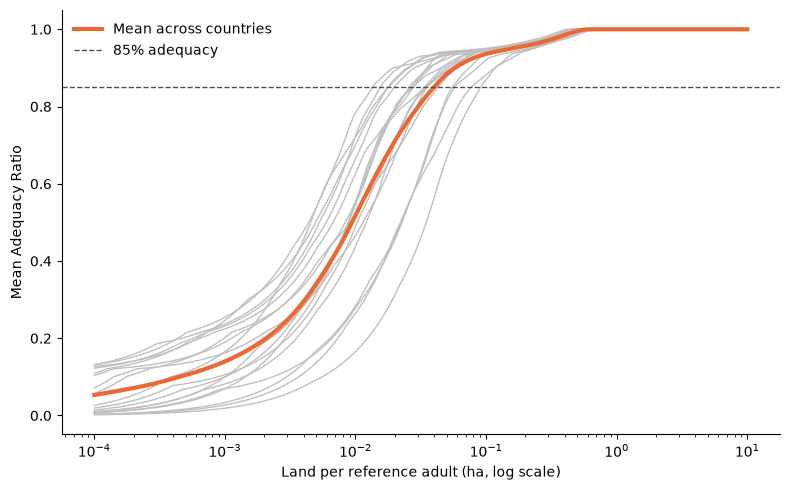

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
mean_mar = np.zeros(len(land_values))
for country, mar in curves.items():
    ax.plot(land_values, mar, color="0.75", linewidth=1)
    mean_mar += np.array(mar)
mean_mar /= len(curves)
ax.plot(land_values, mean_mar, color="#eb6834", linewidth=3, label="Mean across countries")
ax.axhline(0.85, color="0.3", linestyle="--", linewidth=1, label="85% adequacy")
ax.set_xscale("log")
ax.set_xlabel("Land per reference adult (ha, log scale)")
ax.set_ylabel("Mean Adequacy Ratio")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Verify against the paper's own precomputed results

`data/processed/country_mar_wlc.csv` is the exact output the paper's
figure was generated from (same computation, same grid) - comparing
against it directly, rather than only checking these curves "look
reasonable," is a stronger check that this notebook faithfully reproduces
the published methodology.

In [7]:
def min_land_for_target(mar_series, land_values, target):
    vals = np.array(mar_series, dtype=float)
    vals[vals < 0] = np.nan
    ok = np.where(vals >= target)[0]
    return float(land_values[ok[0]]) if len(ok) else np.nan


with open("data/processed/country_mar_wlc.csv", "rb") as f:
    ground_truth = pickle.load(f)

rows = []
for country in curves:
    truth_mar = [m[0] for m in ground_truth[country]]
    mine = min_land_for_target(curves[country], land_values, 0.85)
    truth = min_land_for_target(truth_mar, land_values, 0.85)
    rows.append({"country": country, "min_land_this_notebook": mine, "min_land_published": truth,
                 "ratio": mine / truth if truth else np.nan})

df_check = pd.DataFrame(rows).sort_values("country")
pd.set_option("display.width", 120)
print(df_check.round(4).to_string(index=False))
print(f"\nAll ratios == 1.0000: {(df_check['ratio'].round(4) == 1.0).all()}")

                         country  min_land_this_notebook  min_land_published  ratio
                    Burkina Faso                  0.0365              0.0365    1.0
                         Burundi                  0.0581              0.0581    1.0
                         Comoros                  0.0775              0.0775    1.0
                   Côte d'Ivoire                  0.0435              0.0435    1.0
Democratic Republic of the Congo                  0.0290              0.0290    1.0
                        Ethiopia                  0.0274              0.0274    1.0
                           Ghana                  0.0290              0.0290    1.0
                           Kenya                  0.0183              0.0183    1.0
                          Malawi                  0.0163              0.0163    1.0
                            Mali                  0.0205              0.0205    1.0
                           Niger                  0.0137              0.0137

## 7. Currently cultivated vs. required for adequacy

Compares each country's minimum land for 85% adequacy (from the curves
above, scaled to a household via each country's median adult-male-
equivalent) against the land real surveyed households actually cultivate
today (household survey data, South Africa excluded and rows with
unparseable production values dropped, matching the paper's own
filtering).

In [8]:
df_final = pd.read_csv("data/original/FINAL_results_10-12-2024.csv")
df_req = pd.read_csv("data/original/CLEAN_nut_requirements_HH_10.12.24.csv")
df_land = pd.read_csv("data/indicator_data.csv")

df_final = df_final[df_final["id_country"] != "za"].drop(columns=["fat"])
mask = ~df_final.astype(str).isin(["#NUM!"]).any(axis=1)
df_final = df_final[mask]
id_to_keep = df_final["id_unique"].values

df_req = df_req.query("id_unique in @id_to_keep").drop(columns=["fat", "Unnamed: 0"])
df_land = df_land[["id_unique", "iso_country_code", "land_cultivated_ha", "land_owned_ha", "hh_size_members"]]
df_land = df_land.query("id_unique in @id_to_keep")

df_req = pd.merge(df_req, df_land, on="id_unique", how="left")
iso_to_country = {k: v for k, v in GVARS.iso_to_country.items() if k in df_req["iso_country_code"].unique()}
country_to_iso = {v: k for k, v in iso_to_country.items()}

# adult-male-equivalent, kcal basis
ref = dict(zip(df_dri.drop(columns=["fat"]).columns[2:], (df_dri.iloc[0][2:] * 365).values))
ame = df_req["kcal"] / ref["kcal"]
m = df_req[["id_unique", "iso_country_code", "land_cultivated_ha"]].copy()
m["ame"] = ame.values
agg = m.groupby("iso_country_code").agg(ame_med=("ame", "median"), land_med=("land_cultivated_ha", "median"))

rows = []
for country, curve in curves.items():
    iso = country_to_iso.get(country)
    if iso is None or iso not in agg.index:
        continue
    land_85_per_ame = min_land_for_target(curve, land_values, 0.85)
    ame_med, land_med = agg.loc[iso, "ame_med"], agg.loc[iso, "land_med"]
    land_85_per_hh = land_85_per_ame * ame_med
    rows.append({"country": country, "min_land_85_per_hh": land_85_per_hh,
                 "current_land_per_hh": land_med,
                 "ratio": land_85_per_hh / land_med if land_med else np.nan})

df85 = pd.DataFrame(rows).dropna(subset=["ratio"]).sort_values("ratio")
print(df85.round(4).to_string(index=False))

                         country  min_land_85_per_hh  current_land_per_hh  ratio
                            Mali              0.1622               7.0000 0.0232
                         Senegal              0.1797               7.5000 0.0240
                           Niger              0.0757               3.0000 0.0252
                          Rwanda              0.0880               1.5000 0.0587
                          Malawi              0.0496               0.8000 0.0620
                           Ghana              0.1325               2.0000 0.0662
                          Zambia              0.1368               2.0000 0.0684
     United Republic of Tanzania              0.1494               2.0000 0.0747
                    Burkina Faso              0.2405               3.0000 0.0802
                           Kenya              0.0769               0.8000 0.0961
                        Ethiopia              0.0964               1.0000 0.0964
                         Bur

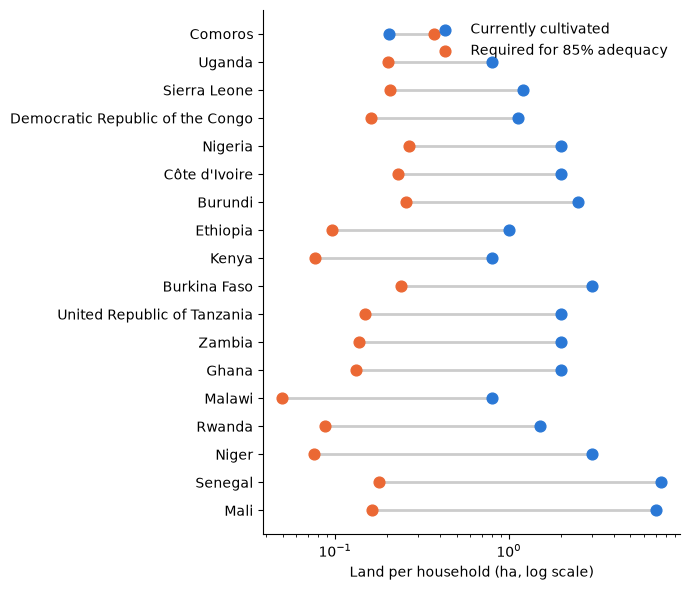

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(df85))
for i, row in enumerate(df85.itertuples()):
    ax.plot([row.current_land_per_hh, row.min_land_85_per_hh], [i, i], color="0.8", linewidth=2, zorder=1)
ax.scatter(df85["current_land_per_hh"], y, color="#2a78d6", s=60, label="Currently cultivated", zorder=2)
ax.scatter(df85["min_land_85_per_hh"], y, color="#eb6834", s=60, label="Required for 85% adequacy", zorder=2)
ax.set_yticks(y); ax.set_yticklabels(df85["country"])
ax.set_xscale("log")
ax.set_xlabel("Land per household (ha, log scale)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Notes

- Household survey data (`data/original/*.csv`, `data/indicator_data.csv`)
  had two columns blanked before inclusion here (a GPS-coordinate column
  and internal survey dataset-linkage IDs) - these carry no information the
  computation above uses, but the raw files shouldn't carry real
  respondents' location data regardless of whether the code reads it.
- For interactive exploration of this same model - adjustable nutrient
  constraints, country selection, household composition, a B12
  counterfactual analysis - see the companion dashboard:
  **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**
